In [1]:
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import rdChemReactions
from rdkit.Chem.Draw import rdMolDraw2D
from rdkit.Chem.Draw import IPythonConsole
from IPython.display import SVG, display
from rxnmapper import RXNMapper

/home/sacharfd/miniconda3/envs/rxnmapper_v2/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# https://gist.github.com/greglandrum/61c1e751b453c623838759609dc41ef1
def draw_chemical_reaction(smiles, highlightByReactant=False, font_scale=1.5):
    rxn = rdChemReactions.ReactionFromSmarts(smiles, useSmiles=True)
    trxn = rdChemReactions.ChemicalReaction(rxn)
    # move atom maps to be annotations:
    for m in trxn.GetReactants():
        moveAtomMapsToNotes(m)
    for m in trxn.GetProducts():
        moveAtomMapsToNotes(m)
    d2d = rdMolDraw2D.MolDraw2DSVG(800, 300)
    d2d.drawOptions().annotationFontScale = font_scale
    d2d.DrawReaction(trxn, highlightByReactant=highlightByReactant)

    d2d.FinishDrawing()

    return d2d.GetDrawingText()


def moveAtomMapsToNotes(m):
    for at in m.GetAtoms():
        if at.GetAtomMapNum():
            at.SetProp("atomNote", str(at.GetAtomMapNum()))

In [3]:
rxn_mapper = RXNMapper()

In [4]:
rxns = [
    "CCOCC.C[Mg+].O=Cc1ccc(F)cc1Cl.[Br-]>>CC(O)c1ccc(F)cc1Cl",
    "BrCCOCCBr.CCN(C(C)C)C(C)C.CCOC(C)=O.CN(C)C=O.Cl.NCC(F)(F)CO>>OCC(F)(F)CN1CCOCC1",
]

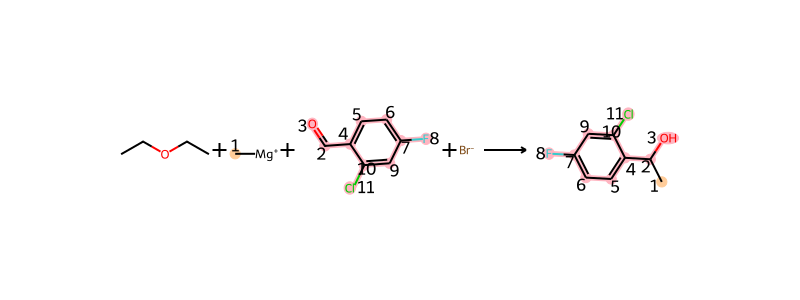

Confidence: 0.94


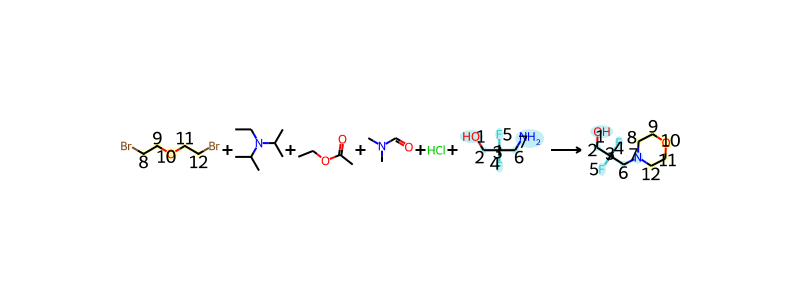

Confidence: 0.51


In [5]:
outputs = rxn_mapper.get_attention_guided_atom_maps(rxns)

for out in outputs:
    display(SVG(draw_chemical_reaction(out["mapped_rxn"], highlightByReactant=True)))
    print(f'Confidence: {out["confidence"]:.2f}')

In [6]:
out["mapped_rxn"]

'Br[CH2:8][CH2:9][O:10][CH2:11][CH2:12]Br.CCN(C(C)C)C(C)C.CCOC(C)=O.CN(C)C=O.Cl.[OH:1][CH2:2][C:3]([F:4])([F:5])[CH2:6][NH2:7]>>[OH:1][CH2:2][C:3]([F:4])([F:5])[CH2:6][N:7]1[CH2:8][CH2:9][O:10][CH2:11][CH2:12]1'